# 05 - Multi-Horizon Forecast

Compare all horizons.


## Setup

In [1]:
import sys, json
sys.path.insert(0, r"D:\\Projects\\done\\eth_bot\\eth_bot_v2")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from analysis.loader import load_ohlcv
from analysis.indicators import add_all

pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (12, 4)
OUT = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "reports" / "forecasts"
OUT.mkdir(parents=True, exist_ok=True)
FEATURES = ["ret_1","ret_5","ret_20","vol_20","rsi_14","macd_hist","atr_14","sma_50","sma_200"]

def build(timeframe="1d", horizon=1):
    df = load_ohlcv(timeframe=timeframe)
    df = add_all(df).copy()
    df["ret_1"]  = df["close"].pct_change(1)
    df["ret_5"]  = df["close"].pct_change(5)
    df["ret_20"] = df["close"].pct_change(20)
    df["vol_20"] = df["ret_1"].rolling(20).std()
    df["target"] = df["close"].pct_change(horizon).shift(-horizon)
    return df.dropna()

def metrics(y, p):
    return {"rmse": float(np.sqrt(((y-p)**2).mean())),
            "mae":  float(np.abs(y-p).mean()),
            "dir_accuracy": float(((p>0)==(y>0)).mean())}

## 1. Fit

In [2]:
HORIZONS = [("1h",1),("1h",4),("1d",1),("1d",3),("1d",7),("1d",30)]
results = []
for tf, h in HORIZONS:
    try:
        df = build(timeframe=tf, horizon=h)
        train = df.iloc[:-250]; test = df.iloc[-250:]
        m = Ridge(alpha=1.0).fit(train[FEATURES].values, train["target"].values)
        p = m.predict(test[FEATURES].values); y = test["target"].values
        mt = metrics(y, p)
        r = float(m.predict(df[FEATURES].iloc[[-1]].values)[0])
        last = float(df["close"].iloc[-1]); rs = float((y-p).std())
        results.append({"timeframe": tf, "horizon": h,
                        "rmse": mt["rmse"], "mae": mt["mae"],
                        "dir_acc": mt["dir_accuracy"],
                        "pred_ret": r, "pred_close": last*(1+r),
                        "p10": last*(1+r-1.28*rs), "p90": last*(1+r+1.28*rs)})
    except Exception as e:
        print(f"{tf}/{h}: failed - {e}")
res = pd.DataFrame(results)
res["direction"] = np.where(res["pred_ret"]>0, "UP", "DOWN")
res

,timeframe,horizon,rmse,mae,dir_acc,pred_ret,pred_close,p10,p90,direction
0,1h,1,0.003977,0.002830,0.484,-0.000075,2681.477540,2667.828953,2695.126128,DOWN
1,1h,4,0.008055,0.005806,0.456,0.000041,2682.101107,2654.479005,2709.723210,UP
2,1d,1,0.032781,0.021877,0.532,0.006254,2723.344636,2609.931768,2836.757505,UP
3,1d,3,0.056511,0.039134,0.528,0.015225,2718.752389,2525.985293,2911.519486,UP
4,1d,7,0.085601,0.059263,0.496,0.013413,2727.712846,2436.841136,3018.584555,UP
5,1d,30,0.185898,0.141267,0.672,0.039216,2485.721205,1951.959440,3019.482970,UP


## 2. Charts

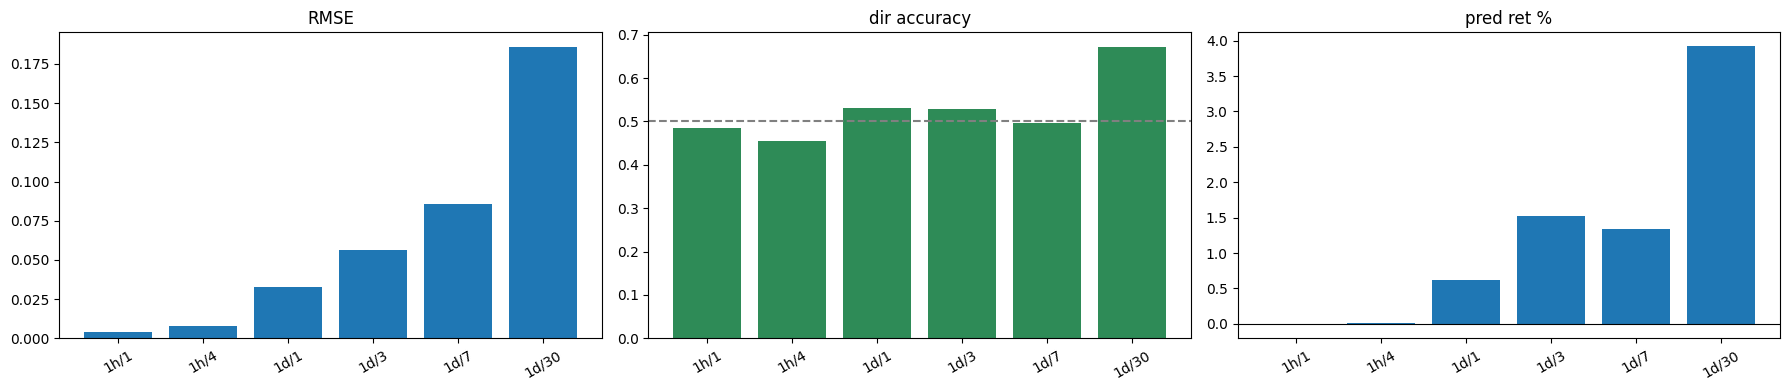

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
labels = [f"{r.timeframe}/{r.horizon}" for r in res.itertuples()]
axes[0].bar(labels, res["rmse"]); axes[0].set_title("RMSE"); axes[0].tick_params(axis="x", rotation=30)
axes[1].bar(labels, res["dir_acc"], color="seagreen")
axes[1].axhline(0.5, ls="--", color="gray"); axes[1].set_title("dir accuracy"); axes[1].tick_params(axis="x", rotation=30)
axes[2].bar(labels, res["pred_ret"]*100)
axes[2].axhline(0, color="black", lw=0.8); axes[2].set_title("pred ret %"); axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 3. Save

In [4]:
(OUT/"multi_horizon.json").write_text(json.dumps(results, indent=2))
print("wrote multi_horizon.json")
res

wrote multi_horizon.json


,timeframe,horizon,rmse,mae,dir_acc,pred_ret,pred_close,p10,p90,direction
0,1h,1,0.003977,0.002830,0.484,-0.000075,2681.477540,2667.828953,2695.126128,DOWN
1,1h,4,0.008055,0.005806,0.456,0.000041,2682.101107,2654.479005,2709.723210,UP
2,1d,1,0.032781,0.021877,0.532,0.006254,2723.344636,2609.931768,2836.757505,UP
3,1d,3,0.056511,0.039134,0.528,0.015225,2718.752389,2525.985293,2911.519486,UP
4,1d,7,0.085601,0.059263,0.496,0.013413,2727.712846,2436.841136,3018.584555,UP
5,1d,30,0.185898,0.141267,0.672,0.039216,2485.721205,1951.959440,3019.482970,UP
